# Construction de la base finale : foncier, PIB et contours des communes

**Projet :** Implantation des hôpitaux, accès aux médecins généralistes et niveau de vie en France métropolitaine, une analyse multi-échelles.

## Objectif de ce notebook

Compléter la base df_final (niveau de vie, APL, population, hôpitaux) avec :
- le **prix du foncier** (transactions DVF) ;
- le **PIB par habitant** (par région) ;
- les **contours des communes**, pour faire des cartes.


## Plan

1. Téléchargement des données
2. Prix du foncier (DVF)
3. PIB par habitant (régions)
4. Table des communes (contours)
5. Assemblage de la base finale
6. Cartes
7. Bilan et suite du travail

## Données utilisées

| Fichier | Source | Contenu |
|---|---|---|
| `communes_2024_50m.geojson` | data.gouv.fr (contours administratifs) | contours des communes, arrondissements de Paris, Lyon et Marseille compris |
| `dvf_2025_france.csv.gz` | data.gouv.fr (demandes de valeurs foncières) | transactions immobilières (fichier 2025) |
| `pib_regions.xlsx` | Insee (PIB 2024, comparaisons régionales) | PIB et PIB par habitant par région |


## 1. Téléchargement des données

On télécharge les quatre fichiers une seule fois dans le dossier data/.
Si un fichier est déjà là, on ne le télécharge pas à nouveau .

### 1.1 Imports et dossier de travail

In [64]:
# Installation 
# %pip install mapclassify geopandas openpyxl

import os
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from matplotlib.colors import ListedColormap

# Dossier où on range les fichiers téléchargés
dossier = Path("data")
dossier.mkdir(exist_ok=True)

### 1.2 Téléchargement des fichiers

In [65]:
def telecharger(url, nom_fichier):
    """Télécharge un fichier et l'enregistre dans le dossier data/ (sauf s'il existe déjà)."""
    chemin = dossier / nom_fichier
    if chemin.exists():                      # inutile de le télécharger deux fois
        print("Déjà présent :", nom_fichier)
        return
    reponse = requests.get(url, timeout=300)
    reponse.raise_for_status()               # arrête le programme si le lien est cassé
    chemin.write_bytes(reponse.content)
    print("Téléchargé :", nom_fichier)

# Liste des fichiers : (adresse, nom sur mon ordinateur)
fichiers = [
    ("https://www.data.gouv.fr/api/1/datasets/r/54499806-3eae-4f3a-9475-d891d795e71d",
     "communes_2024_50m.geojson"),
    ("https://www.insee.fr/fr/statistiques/fichier/8217527/DS_BPE_CSV_FR.zip",
     "bpe.zip"),
    ("https://www.insee.fr/fr/statistiques/fichier/2012723/TCR_062.xlsx",
     "pib_regions.xlsx"),
    ("https://www.data.gouv.fr/api/1/datasets/r/b3a0c6d2-2a5a-45a3-81a8-9e860caf5e14",
     "dvf_2025_france.csv.gz"),
]

for url, nom in fichiers:
    telecharger(url, nom)

Déjà présent : communes_2024_50m.geojson
Déjà présent : bpe.zip
Déjà présent : pib_regions.xlsx
Déjà présent : dvf_2025_france.csv.gz


## 2. Prix du foncier (DVF)

La base DVF contient les ventes immobilières. On veut un **prix au m² médian par commune**.

On procède en cinq étapes : lecture, filtres, calcul du prix au m², regroupement des arrondissements, médianes.

**Limite :** DVF ne contient pas l'Alsace-Moselle (départements 57, 67 et 68). Ces communes n'auront pas de prix.

### 2.1 Lecture des colonnes utiles

In [66]:
# On lit seulement les colonnes dont on a besoin (le fichier est très gros)
colonnes = ["id_mutation", "nature_mutation", "valeur_fonciere", "code_commune",
            "code_departement", "type_local", "surface_reelle_bati"]

# Les codes sont lus en texte pour garder les zéros du début (ex : 01001)
dvf = pd.read_csv("data/dvf_2025_france.csv.gz", usecols=colonnes,
                  dtype={"code_commune": str, "code_departement": str})
print(len(dvf), "lignes lues")

3793113 lignes lues


### 2.2 Filtres

On garde uniquement des ventes de logements dont le prix et la surface sont exploitables.

In [67]:
# 1. On garde les ventes de logements (appartements et maisons)
dvf = dvf[dvf["nature_mutation"] == "Vente"]
dvf = dvf[dvf["type_local"].isin(["Appartement", "Maison"])]

# 2. On garde les surfaces et les prix positifs
dvf = dvf[(dvf["surface_reelle_bati"] > 0) & (dvf["valeur_fonciere"] > 0)]

# 3. On garde les ventes d'un seul logement (une seule ligne par id_mutation)
#    duplicated(keep=False) met True sur toutes les lignes en double, et ~ inverse le résultat
dvf = dvf[~dvf["id_mutation"].duplicated(keep=False)]

print(len(dvf), "ventes retenues")

757913 ventes retenues


### 2.3 Prix au m²

In [68]:
# Prix au m² = prix de vente / surface du bâti
dvf["prix_m2"] = dvf["valeur_fonciere"] / dvf["surface_reelle_bati"]
print(dvf["prix_m2"].describe().round(0))

# Filtre possible sur les prix aberrants (à décider en équipe, pas utilisé pour l'instant) :
# dvf = dvf[(dvf["prix_m2"] > 500) & (dvf["prix_m2"] < 30000)]

count     757913.0
mean        3335.0
std         6370.0
min            0.0
25%         1696.0
50%         2636.0
75%         3994.0
max      3210526.0
Name: prix_m2, dtype: float64


**Remarque :** le minimum est 0 et le maximum dépasse 3 millions d'euros le m². Ce sont des valeurs aberrantes (erreurs de saisie).
On utilise donc la **médiane** plutôt que la moyenne, car elle y est peu sensible.

### 2.4 Regroupement des arrondissements

Dans DVF, Paris, Lyon et Marseille sont codées par arrondissement. Le reste de la base est au niveau commune.
On crée donc un code « commune » qui regroupe les arrondissements, tout en gardant le code d'origine.

In [69]:
def regrouper(code):
    """Remplace le code d'un arrondissement par celui de sa ville (Paris, Lyon, Marseille)."""
    if code.startswith("751"):
        return "75056"      # Paris
    if code.startswith("6938"):
        return "69123"      # Lyon
    if code.startswith("132"):
        return "13055"      # Marseille
    return code             # les autres communes ne changent pas

dvf["code_com"] = dvf["code_commune"].apply(regrouper)

### 2.5 Médianes par zone

On calcule la médiane du prix au m² par arrondissement, par commune et par département, ainsi que le nombre de ventes par commune.

In [70]:
# Arrondissements : lignes dont le code a changé avec la fonction regrouper
arrondissements = dvf[dvf["code_commune"] != dvf["code_com"]]
prix_arr = arrondissements.groupby("code_commune")["prix_m2"].median()

# Communes (Paris, Lyon et Marseille comptées comme une seule commune)
prix_com = dvf.groupby("code_com")["prix_m2"].median()
nb_ventes = dvf.groupby("code_com").size()

# Départements
prix_dep = dvf.groupby("code_departement")["prix_m2"].median()

print(len(prix_arr), "arrondissements,", len(prix_com), "communes,", len(prix_dep), "départements")

45 arrondissements, 29264 communes, 97 départements


## 3. PIB par habitant (régions)

Le fichier de l'Insee utilisé ici donne le PIB par habitant **par région**.
Toutes les communes d'une même région auront donc la même valeur.

### 3.1 Lecture du fichier brut

On regarde d'abord le fichier tel quel, pour repérer où sont les données (il y a des lignes de titre au début).

In [71]:
pib_brut = pd.read_excel("data/pib_regions.xlsx", sheet_name="REG", header=None)
print(pib_brut.shape)
pib_brut.head(10)

(29, 8)


,0,1,2,3,4,5,6,7
0,Produit intérieur brut en 2024 : comparaisons ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,PIB (millions d'euros),NaN,PIB par habitant (euros),NaN,PIB par emploi (euros),NaN
4,NaN,NaN,2024,2023.0,2024,2023.0,2024,2023.0
5,84,Auvergne-Rhône-Alpes,346405,336643.0,41949,40944.0,92972,91017.0
6,27,Bourgogne-Franche-Comté,95775,93225.0,34216,33260.0,85490,83873.0
7,53,Bretagne,126549,122021.0,36552,35429.0,84226,81850.0
8,24,Centre-Val de Loire,91467,89691.0,35451,34750.0,87278,86274.0
9,94,Corse,13358,12733.0,37470,35970.0,91933,88243.0


### 3.2 Nettoyage

On garde trois colonnes : le code de la région, son nom et le PIB par habitant en 2024.

In [72]:
# Les données commencent à la ligne 5 ; colonnes 0 (code), 1 (nom) et 4 (PIB par habitant 2024)
pib_reg = pib_brut.iloc[5:, [0, 1, 4]].copy()
pib_reg.columns = ["code_region", "region", "pib_hab_2024"]

# Codes en texte (sans le ".0") et PIB en nombres
pib_reg["code_region"] = pib_reg["code_region"].astype(str).str.replace(".0", "", regex=False)
pib_reg["pib_hab_2024"] = pd.to_numeric(pib_reg["pib_hab_2024"], errors="coerce")
pib_reg = pib_reg.dropna(subset=["pib_hab_2024"])          # enlève les lignes vides

# Lignes de total à enlever : P (France métropolitaine hors Île-de-France),
# M (France métropolitaine) et F (France)
pib_reg = pib_reg[~pib_reg["code_region"].isin(["P", "M", "F"])]

# Dictionnaire : code région -> PIB par habitant
reg_pib = pib_reg.set_index("code_region")["pib_hab_2024"]
print(pib_reg.to_string())

   code_region                               region  pib_hab_2024
5           84                 Auvergne-Rhône-Alpes       41949.0
6           27              Bourgogne-Franche-Comté       34216.0
7           53                             Bretagne       36552.0
8           24                  Centre-Val de Loire       35451.0
9           94                                Corse       37470.0
10          44                            Grand Est       35431.0
11          32                      Hauts-de-France       32891.0
12          11                        Île-de-France       69514.0
13          28                            Normandie       35287.0
14          75                   Nouvelle-Aquitaine       36206.0
15          76                            Occitanie       35934.0
16          52                     Pays de la Loire       37541.0
17          93           Provence-Alpes-Côte d'Azur       41818.0
20          01  Guadeloupe (y compris Saint-Martin)       29099.0
21        

## 4. Table des communes (contours)

Le fichier de contours donne, pour chaque commune, son département et sa région.
On s'en sert pour créer une **table de passage** (pont) entre le code commune et le PIB de sa région.
Elle servira à compléter les communes dont la région manque dans df_final.

### 4.1 Lecture des contours

In [73]:
# Les contours sont gardés pour faire les cartes 
contours = gpd.read_file("data/communes_2024_50m.geojson")

# Version sans la géométrie : une simple table avec le code, le nom, le département et la région
table_communes = pd.DataFrame(contours.drop(columns="geometry"))
print(table_communes[["code", "nom", "departement", "region"]].head())

    code                      nom departement region
0  01001  L'Abergement-Clémenciat          01     84
1  01002    L'Abergement-de-Varey          01     84
2  01004        Ambérieu-en-Bugey          01     84
3  01005      Ambérieux-en-Dombes          01     84
4  01006                  Ambléon          01     84


### 4.2 Table de passage commune à PIB

In [74]:
pont = table_communes[["code", "departement", "region"]].copy()
pont["pib_hab"] = pont["region"].map(reg_pib)          # PIB de la région de chaque commune

# Contrôle : Marseille, Lyon, Paris et un arrondissement de Paris
print(pont["pib_hab"].isna().sum(), "communes sans PIB")
print(pont[pont["code"].isin(["75056", "75111", "69123", "13055"])])

111 communes sans PIB
        code departement region  pib_hab
4342   13055          13     93  41818.0
27098  69123          69     84  41949.0
29269  75056          75     11  69514.0
29280  75111          75     11  69514.0


In [75]:
# Quelles communes n'ont pas de PIB ?
sans = pont[pont["pib_hab"].isna()]
print(sans["region"].value_counts())

region
987    48
988    33
06     17
984     5
986     3
975     2
977     1
978     1
989     1
Name: count, dtype: int64


Le tableau de l’Insee ne contient que les 13 régions métropolitaines et 4 régions d’outre-mer (Guadeloupe, Martinique, Guyane, La Réunion). Mayotte et les collectivités d’outre-mer n’y figurent pas.

## 5. Assemblage de la base finale

On part de df_final (créée par fusion.py) et on lui ajoute le prix du foncier et le PIB.

### 5.1 Chargement de la base

In [76]:
# On lit tout en texte (dtype=str) pour ne pas perdre les zéros des codes ; on convertit plus bas
df_final = pd.read_excel("../data/processed/df_final.xlsx", dtype=str)
print(df_final.shape)

(34768, 15)


### 5.2 Ajout du prix au m², du nombre de ventes et du PIB

In [77]:
# map() cherche, pour chaque commune, sa valeur dans le dictionnaire correspondant
df_final["prix_m2_median"] = df_final["COM_INSEE"].map(prix_com)
df_final["nb_ventes"] = df_final["COM_INSEE"].map(nb_ventes)
df_final["pib_hab"] = df_final["REG"].map(reg_pib)       # PIB de la région de la commune

# Contrôles
print(df_final.shape)
print(df_final[["prix_m2_median", "nb_ventes", "pib_hab"]].isna().sum())
print(df_final[df_final["COM_INSEE"].isin(["75056", "69123", "13055"])]
      [["COM_INSEE", "commune", "prix_m2_median", "pib_hab", "apl"]])

(34768, 18)
prix_m2_median    5585
nb_ventes         5585
pib_hab             34
dtype: int64
      COM_INSEE    commune  prix_m2_median  pib_hab                apl
4069      13055  Marseille     3313.839489  41818.0  5.201306138207334
27391     69123       Lyon     4471.428571  41949.0  4.600774702697755
29004     75056      Paris     9700.000000  69514.0  5.496621471353419


### 5.3 Compléter les PIB manquants

Quelques communes n'ont pas de région dans df_final : on cherche leur PIB avec la table de passage pont.

In [78]:
# Table de recherche : pour chaque code commune, le PIB par habitant de sa région
# (pont vient des contours 2024 ; set_index met le code en étiquette de ligne)
pib_par_commune = pont.set_index("code")["pib_hab"]

# les communes de df_final dont le PIB est vide
manque = df_final["pib_hab"].isna()

# Pour ces communes seulement :
#   - on prend leur code commune (COM_INSEE)
#   - map() cherche ce code dans pib_par_commune et renvoie le PIB trouvé
#   - on écrit le résultat dans la colonne pib_hab
# Les communes qui avaient déjà un PIB ne changent pas ;
# si un code n'est pas dans pont, le PIB reste vide (NaN)
df_final.loc[manque, "pib_hab"] = df_final.loc[manque, "COM_INSEE"].map(pib_par_commune)

print(df_final["pib_hab"].isna().sum(), "communes sans PIB")
print(df_final[df_final["pib_hab"].isna()][["COM_INSEE", "commune", "DEP", "REG"]])

4 communes sans PIB
    COM_INSEE commune  DEP  REG
615     15035     NaN  NaN  NaN
628     15047     NaN  NaN  NaN
638     15171     NaN  NaN  NaN
644     15031     NaN  NaN  NaN


4 communes du Cantal n’apparaissent ni dans le fichier APL ni dans les contours 2024 (probablement un changement de code).

### 5.4 Compléter les départements manquants

In [79]:
# Le département correspond aux deux premiers caractères du code commune (2A et 2B pour la Corse)
df_final["DEP"] = df_final["DEP"].fillna(df_final["COM_INSEE"].str[:2])

### 5.5 Colonnes en nombres

Comme la base a été lue en texte, on convertit les colonnes numériques.

In [80]:
colonnes_numeriques = ["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot",
                       "revenu_median", "prix_m2_median", "nb_ventes", "pib_hab", "nb_hopitaux"]

for col in colonnes_numeriques:
    if col in df_final.columns:
        # on remplace la virgule décimale par un point, puis on convertit
        df_final[col] = pd.to_numeric(
            df_final[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")#on convertit en str pour remplacer 

# Ces deux colonnes valent toujours "COM" et "MED_SL" : on les supprime
df_final = df_final.drop(columns=["GEO_OBJECT", "FILOSOFI_MEASURE"], errors="ignore")

print(df_final.dtypes)

COM_INSEE             str
revenu_median     float64
commune               str
apl               float64
apl65             float64
apl62             float64
apl60             float64
pop_std           float64
pop_tot           float64
DEP                   str
REG                   str
ARR                   str
nb_hopitaux         int64
prix_m2_median    float64
nb_ventes         float64
pib_hab           float64
dtype: object


### 5.6 Contrôle des valeurs manquantes

In [81]:
# Nombre de valeurs manquantes par colonne
df_final.isna().sum()

COM_INSEE            0
revenu_median     3974
commune             10
apl                 10
apl65               10
apl62               10
apl60               10
pop_std             10
pop_tot             10
DEP                  0
REG                 10
ARR                 10
nb_hopitaux          0
prix_m2_median    5585
nb_ventes         5585
pib_hab              4
dtype: int64

### 5.7 Enregistrement de la base

On l'enregistre en CSV 

In [82]:
df_final.to_csv("../data/processed/df_final3.csv", index=False, encoding="utf-8-sig")
print("Base enregistrée :", df_final.shape)

Base enregistrée : (34768, 16)


## 6. Cartes

On associe la base aux contours des communes, puis on trace trois cartes : l'APL, le niveau de vie et le prix du foncier.

### 6.1 Jointure avec les contours

In [83]:
# On garde le code et la géométrie des contours
communes = contours[["code", "geometry"]]

# France métropolitaine seulement (on enlève les DOM, codes qui commencent par 97)
d = df_final[~df_final["COM_INSEE"].str.startswith("97")]

# Jointure : chaque commune récupère sa géométrie
gc = communes.merge(d, left_on="code", right_on="COM_INSEE", how="inner")
print(len(d), "communes dans la base,", len(gc), "avec un contour")

34744 communes dans la base, 34736 avec un contour


### 6.2 Fonctions pour tracer les cartes

In [84]:
def enregistrer(fichier):
    """Enregistre la figure dans un fichier (le dossier est créé s'il n'existe pas)."""
    if fichier:
        os.makedirs(os.path.dirname(fichier), exist_ok=True)
        plt.savefig(fichier, dpi=200, bbox_inches="tight")


def carte(gdf, col, titre, cmap="viridis", k=7, fichier=None):
    """Carte par classes de même effectif (quantiles) : pour le revenu, le foncier..."""
    ax = gdf.plot(column=col, cmap=cmap, scheme="quantiles", k=k, legend=True,
                  linewidth=0, figsize=(9, 9),
                  missing_kwds={"color": "lightgrey", "label": "pas de donnée"})
    ax.set_title(titre)
    ax.set_axis_off()
    enregistrer(fichier)
    plt.show()


def carte_apl(gdf, titre="Accès aux généralistes (APL) par commune", fichier=None):
    """Carte de l'APL avec les trois classes de la DREES."""
    classe = pd.cut(gdf["apl"], [-0.01, 2.5, 4, np.inf],
                    labels=["sous-dotée (≤ 2,5)", "moyennement dotée (2,5 à 4)", "bien dotée (> 4)"])
    ax = gdf.assign(classe_apl=classe).plot(
        column="classe_apl", categorical=True, legend=True,
        cmap=ListedColormap(["#d73027", "#fee08b", "#1a9850"]),
        linewidth=0, figsize=(9, 9), missing_kwds={"color": "lightgrey"},
        legend_kwds={"loc": "lower left"})
    ax.set_title(titre)
    ax.set_axis_off()
    enregistrer(fichier)
    plt.show()

### 6.3 Les trois cartes

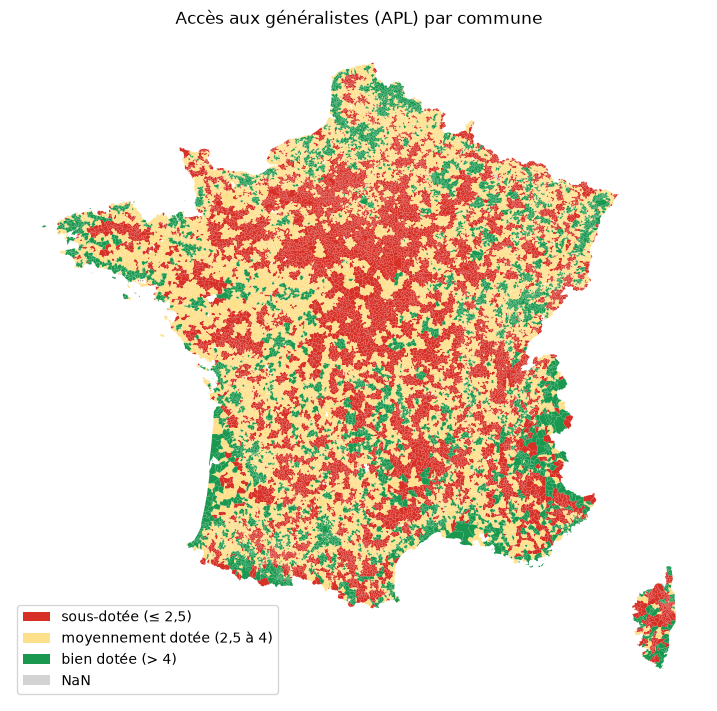

In [85]:
carte_apl(gc, fichier="../figures/apl_communes.png")

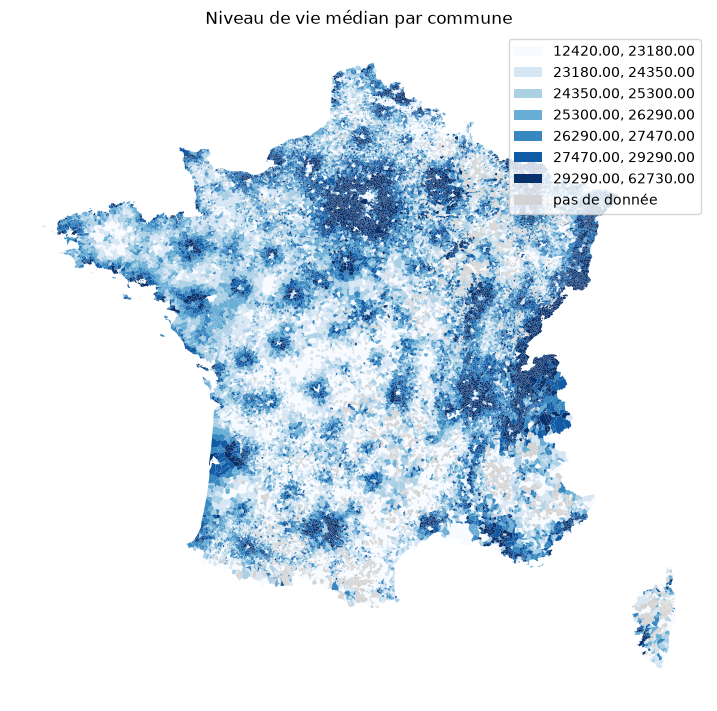

In [86]:
carte(gc, "revenu_median", "Niveau de vie médian par commune", cmap="Blues",
      fichier="../figures/revenu_communes.png")

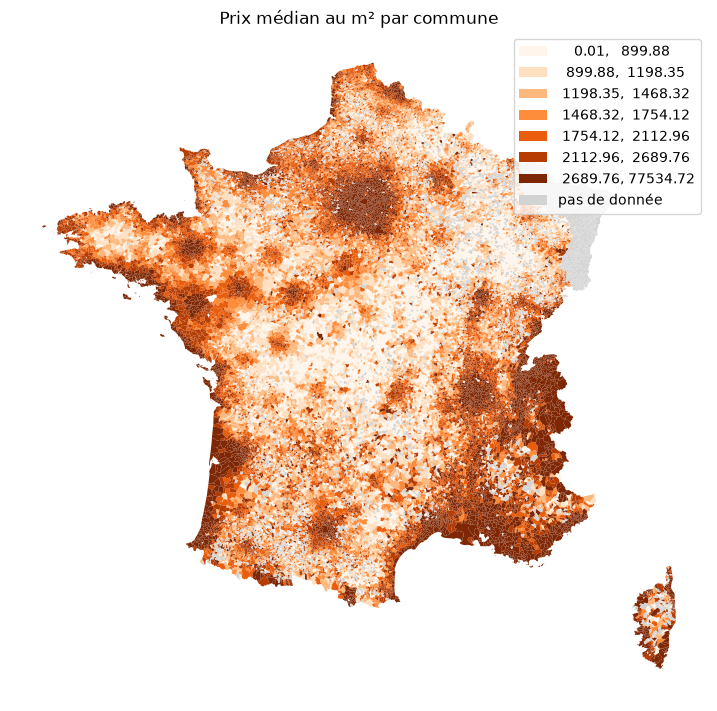

In [87]:
carte(gc, "prix_m2_median", "Prix médian au m² par commune", cmap="Oranges",
      fichier="../figures/prix_communes.png")

In [88]:
# 1. Taille et doublons
print(df_final.shape)
print("Doublons de commune :", df_final["COM_INSEE"].duplicated().sum())      # attendu : 0

# 2. Types : les colonnes de chiffres doivent être des nombres
colonnes_num = ["revenu_median", "apl", "apl65", "apl62", "apl60",
                "pop_std", "pop_tot", "nb_hopitaux", "prix_m2_median", "pib_hab"]
for col in colonnes_num:
    df_final[col] = pd.to_numeric(df_final[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print(df_final[colonnes_num].dtypes)

# 3. Valeurs manquantes par colonne
print(df_final[colonnes_num].isna().sum())

# 4. Valeurs plausibles (min, médiane, max)
print(df_final[colonnes_num].describe().round(1).T[["min", "50%", "max"]])

# 5. Le code commune garde ses zéros (5 caractères)
print(df_final["COM_INSEE"].str.len().value_counts())                           # attendu : tout à 5

# 6. Paris, Lyon, Marseille
print(df_final[df_final["COM_INSEE"].isin(["75056", "69123", "13055"])][
    ["COM_INSEE", "commune", "apl", "pop_tot", "nb_hopitaux", "prix_m2_median", "pib_hab"]])

# 7. Totaux : comparaison avec des ordres de grandeur connus
print("Population totale :", round(df_final["pop_tot"].sum() / 1e6, 1), "millions")
print("Hôpitaux au total :", int(df_final["nb_hopitaux"].sum()))

(34768, 16)
Doublons de commune : 0
revenu_median     float64
apl               float64
apl65             float64
apl62             float64
apl60             float64
pop_std           float64
pop_tot           float64
nb_hopitaux         int64
prix_m2_median    float64
pib_hab           float64
dtype: object
revenu_median     3974
apl                 10
apl65               10
apl62               10
apl60               10
pop_std             10
pop_tot             10
nb_hopitaux          0
prix_m2_median    5585
pib_hab              4
dtype: int64
                    min      50%        max
revenu_median   12420.0  25780.0    62730.0
apl                 0.0      2.8       23.9
apl65               0.0      2.5       23.9
apl62               0.0      2.2       23.9
apl60               0.0      2.0       15.9
pop_std             1.9    462.3  2062654.3
pop_tot             2.0    457.0  2113705.0
nb_hopitaux         0.0      0.0       76.0
prix_m2_median      0.0   1608.3    77534.7
pib_hab